# Model MLP Prediksi Risiko Stroke
**Tim Eureka · Bagian 2: Model · John Alpha Varensius Purba (231110795)**

Notebook ini melatih **tiga model MLP** dengan arsitektur dan konfigurasi sama persis. Yang beda hanya cara menangani kelas yang timpang:

| Berkas | Perlakuan |
|---|---|
| `model_dasar.keras` | loss biasa, tanpa perlakuan |
| `model_weighted.keras` | loss biasa + `class_weight` |
| `model_focal.keras` | **focal loss** (fitur unik 1) |

Ketiganya diserahkan ke Sherly untuk dievaluasi. **Data test tidak disentuh di notebook ini**: itu dibuka sekali oleh Sherly di akhir.

Dataset: [Stroke Prediction Dataset (fedesoriano, Kaggle)](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset)

## 1. Persiapan
`PAKAI_DATA_BAGAS = True` memakai `train.npz` dan `val.npz` dari Bagas (`test.npz` tidak dipakai, itu milik Sherly). Kalau `False`, notebook membuat **data sementara** sendiri dari CSV mentah.

In [ ]:
import json
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
PAKAI_DATA_BAGAS = True

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.13.2


## 2. Data
**Data sementara** meniru versi kasar tugas Bagas: buang `id`, buang 1 baris `gender = Other`, isi BMI kosong dengan median data latih, one-hot, standardisasi dari data latih saja, split 70/15/15 berstrata dengan seed 42.

Sel berikut membuka jendela unggah kalau berkasnya belum ada di Colab:
- data Bagas: pilih **`train.npz` dan `val.npz`** sekaligus (tahan Ctrl saat memilih);
- data sementara: pilih `healthcare-dataset-stroke-data.csv`.

In [ ]:
CSV = Path("healthcare-dataset-stroke-data.csv")
DIR_BAGAS = Path("data/processed")

if PAKAI_DATA_BAGAS and not (DIR_BAGAS / "train.npz").exists():
    from google.colab import files
    DIR_BAGAS.mkdir(parents=True, exist_ok=True)
    for nama, isi in files.upload().items():
        (DIR_BAGAS / nama).write_bytes(isi)
elif not PAKAI_DATA_BAGAS and not CSV.exists():
    from google.colab import files
    files.upload()

Saving train.npz to train.npz
Saving val.npz to val.npz


In [ ]:
def data_sementara(csv):
    df = pd.read_csv(csv, na_values=["N/A"]).drop(columns="id")
    df = df[df["gender"] != "Other"]
    y = df.pop("stroke").to_numpy("float32")

    X_tr, X_sisa, y_tr, y_sisa = train_test_split(df, y, test_size=0.30, stratify=y, random_state=SEED)
    X_va, _, y_va, _ = train_test_split(X_sisa, y_sisa, test_size=0.50, stratify=y_sisa, random_state=SEED)

    num = ["age", "avg_glucose_level", "bmi"]
    cat = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
    prep = ColumnTransformer(
        [("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    prep.fit(X_tr)
    ubah = lambda X: prep.transform(X).astype("float32")
    return ubah(X_tr), y_tr, ubah(X_va), y_va, prep.get_feature_names_out()


if PAKAI_DATA_BAGAS:
    d_tr, d_va = np.load(DIR_BAGAS / "train.npz"), np.load(DIR_BAGAS / "val.npz")
    X_tr, y_tr = d_tr["X"].astype("float32"), d_tr["y"].astype("float32")
    X_va, y_va = d_va["X"].astype("float32"), d_va["y"].astype("float32")
    fitur = d_tr["feature_names"] if "feature_names" in d_tr else None
    OUT = Path("artifacts")
else:
    X_tr, y_tr, X_va, y_va, fitur = data_sementara(CSV)
    OUT = Path("artifacts/dev")
OUT.mkdir(parents=True, exist_ok=True)

assert X_tr.shape[1] == X_va.shape[1], "jumlah fitur train dan val beda"
assert set(np.unique(y_tr)) == {0.0, 1.0}, "label harus 0/1"
assert not np.isnan(X_tr).any() and not np.isnan(X_va).any(), "ada NaN di data"

N_FITUR = X_tr.shape[1]
n0, n1 = np.bincount(y_tr.astype(int))
print(f"Latih   : {len(y_tr)} baris, {int(y_tr.sum())} stroke")
print(f"Validasi: {len(y_va)} baris, {int(y_va.sum())} stroke")
print(f"Jumlah fitur: {N_FITUR}")
if fitur is not None:
    print(list(fitur))

Latih   : 3576 baris, 174 stroke
Validasi: 766 baris, 37 stroke
Jumlah fitur: 15


## 3. Focal loss (fitur unik 1)
Focal loss adalah binary cross-entropy yang dikali faktor $(1-p_t)^\gamma$:

$$FL(p_t) = -\alpha_t\,(1-p_t)^\gamma \log(p_t)$$

- $p_t$: peluang yang diberikan model ke kelas yang benar.
- Pasien yang sudah mudah ditebak benar ($p_t$ mendekati 1) sumbangan loss-nya mengecil, jadi training lebih fokus ke pasien yang sulit, termasuk kasus stroke yang langka.
- $\gamma = 0$ membuat focal loss sama dengan binary cross-entropy biasa.
- $\alpha$ adalah bobot untuk kelas **stroke** (kelas normal mendapat $1-\alpha$).

Dipakai versi bawaan Keras supaya model tersimpan bisa dimuat Sherly dan Irfan tanpa kode tambahan.

In [ ]:
def focal_loss(gamma=2.0, alpha=0.25):
    return keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=alpha, gamma=gamma)

## 4. Arsitektur MLP
2 hidden layer. Tiap hidden layer: **Dense (tanpa bias) → BatchNorm → ReLU → Dropout**, dengan L2 pada bobot Dense (materi pertemuan 3 dan 4). Output: 1 neuron sigmoid, tanpa BatchNorm dan Dropout.

In [ ]:
CONFIG = dict(units=[32, 16], dropout=0.2, l2=1e-4, lr=1e-3, batch=64,
              epochs=200, patience=15, gamma=2.0, alpha=0.25)


def bangun_model(n_fitur, units=(32, 16), dropout=0.2, l2=1e-4):
    reg = keras.regularizers.L2(l2)
    blok = [keras.Input(shape=(n_fitur,))]
    for u in units:
        blok += [
            layers.Dense(u, use_bias=False, kernel_regularizer=reg),  # beta milik BN sudah berperan sebagai bias
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.Dropout(dropout),
        ]
    blok.append(layers.Dense(1, activation="sigmoid"))
    return keras.Sequential(blok, name="mlp_stroke")


contoh = bangun_model(N_FITUR, CONFIG["units"], CONFIG["dropout"], CONFIG["l2"])
contoh.summary()

Model: "mlp_stroke"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,201 (4.69 KB)

 Trainable params: 1,105 (4.32 KB)

 Non-trainable params: 96 (384.00 B)

### Cek jumlah parameter (wajib sama dengan diagram di laporan)
| Layer | Rumus |
|---|---|
| Dense 1 (tanpa bias) | fitur × u1 |
| BatchNorm 1 | 4 × u1 (γ, β dilatih; mean, variance tidak) |
| Dense 2 (tanpa bias) | u1 × u2 |
| BatchNorm 2 | 4 × u2 |
| Output | u2 × 1 + 1 bias |

In [ ]:
u1, u2 = CONFIG["units"]
rincian = {
    "Dense 1": N_FITUR * u1,
    "BatchNorm 1": 4 * u1,
    "Dense 2": u1 * u2,
    "BatchNorm 2": 4 * u2,
    "Output": u2 + 1,
}
for nama, n in rincian.items():
    print(f"{nama:12s} {n:6d}")
manual = sum(rincian.values())
trainable = int(sum(np.prod(w.shape) for w in contoh.trainable_weights))
print(f"Total manual : {manual}\nTotal Keras  : {contoh.count_params()} (trainable {trainable})")
assert manual == contoh.count_params(), "hitungan manual beda dengan Keras"

Dense 1         480
BatchNorm 1     128
Dense 2         512
BatchNorm 2      64
Output           17
Total manual : 1201
Total Keras  : 1201 (trainable 1105)


## 5. Melatih tiga model
- Seed diset ulang sebelum tiap model, jadi bobot awal ketiganya sama: perbandingan adil.
- Data latih diacak ulang tiap epoch lewat `tf.data` (jebakan seed di materi pertemuan 5).
- EarlyStopping memantau `val_auc_pr` dan mengembalikan bobot terbaik.

In [ ]:
def latih(loss, class_weight=None, verbose=2):
    keras.utils.set_random_seed(SEED)
    model = bangun_model(N_FITUR, CONFIG["units"], CONFIG["dropout"], CONFIG["l2"])
    model.compile(
        optimizer=keras.optimizers.Adam(CONFIG["lr"]),
        loss=loss,
        metrics=[keras.metrics.AUC(curve="PR", name="auc_pr"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.Precision(name="precision")],
    )
    train_ds = (tf.data.Dataset.from_tensor_slices((X_tr, y_tr))
                .shuffle(len(X_tr), seed=SEED, reshuffle_each_iteration=True)
                .batch(CONFIG["batch"]).prefetch(1))
    es = keras.callbacks.EarlyStopping(monitor="val_auc_pr", mode="max",
                                       patience=CONFIG["patience"], restore_best_weights=True)
    h = model.fit(train_ds, validation_data=(X_va, y_va), epochs=CONFIG["epochs"],
                  class_weight=class_weight, callbacks=[es], verbose=verbose)
    return model, {k: [float(x) for x in v] for k, v in h.history.items()}


VARIAN = {
    "dasar": dict(loss="binary_crossentropy", class_weight=None),
    "weighted": dict(loss="binary_crossentropy", class_weight={0: 1.0, 1: float(n0 / n1)}),
    "focal": dict(loss=focal_loss(CONFIG["gamma"], CONFIG["alpha"]), class_weight=None),
}

log = dict(config=CONFIG, seed=SEED, data="bagas" if PAKAI_DATA_BAGAS else "sementara",
           n_fitur=N_FITUR, latih=dict(tidak_stroke=int(n0), stroke=int(n1)), model={})

for nama, v in VARIAN.items():
    print(f"\n=== model_{nama} ===")
    model, hist = latih(v["loss"], v["class_weight"])
    model.save(OUT / f"model_{nama}.keras")
    terbaik = int(np.argmax(hist["val_auc_pr"]))
    log["model"][nama] = dict(
        class_weight=v["class_weight"],
        parameter_total=int(model.count_params()),
        epoch_jalan=len(hist["loss"]),
        epoch_terbaik=terbaik + 1,
        val_auc_pr=hist["val_auc_pr"][terbaik],
        val_recall=hist["val_recall"][terbaik],
        val_precision=hist["val_precision"][terbaik],
        history=hist,  # untuk kurva loss latih vs validasi (Sherly)
    )

(OUT / "train_log.json").write_text(json.dumps(log, indent=2))
print("\nTersimpan di", OUT)


=== model_dasar ===
Epoch 1/200
56/56 - 6s - 100ms/step - auc_pr: 0.0562 - loss: 0.5002 - precision: 0.0526 - recall: 0.2069 - val_auc_pr: 0.0849 - val_loss: 0.5002 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/200
56/56 - 0s - 7ms/step - auc_pr: 0.0722 - loss: 0.3464 - precision: 0.0758 - recall: 0.0920 - val_auc_pr: 0.1226 - val_loss: 0.3489 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/200
56/56 - 0s - 6ms/step - auc_pr: 0.0863 - loss: 0.2697 - precision: 0.0426 - recall: 0.0115 - val_auc_pr: 0.1447 - val_loss: 0.2734 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/200
56/56 - 0s - 7ms/step - auc_pr: 0.0971 - loss: 0.2359 - precision: 0.1282 - recall: 0.0287 - val_auc_pr: 0.2049 - val_loss: 0.2252 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/200
56/56 - 0s - 7ms/step - auc_pr: 0.0897 - loss: 0.2185 - precision: 0.0909 - recall: 0.0115 - val_auc_pr: 0.2034 - val_loss: 0.2025 - val_precision: 0.0000e+00 - val_recall: 0.0000e+

## 6. Ringkasan (data validasi)
Angka ini **hanya untuk mengecek** bahwa training berjalan. Angka resmi untuk laporan datang dari `metrics.json` buatan Sherly. Recall dan precision di sini memakai ambang bawaan 0,5. Sebagai patokan, PR-AUC model acak sekitar 0,05.

In [ ]:
ringkas = pd.DataFrame({
    f"model_{n}": {k: m[k] for k in ["val_auc_pr", "val_recall", "val_precision", "epoch_terbaik", "epoch_jalan", "parameter_total"]}
    for n, m in log["model"].items()
}).T
ringkas.round(3)

,val_auc_pr,val_recall,val_precision,epoch_terbaik,epoch_jalan,parameter_total
model_dasar,0.223,0.000,0.000,30.0,45.0,1201.0
model_weighted,0.278,0.757,0.117,47.0,62.0,1201.0
model_focal,0.208,0.000,0.000,38.0,53.0,1201.0


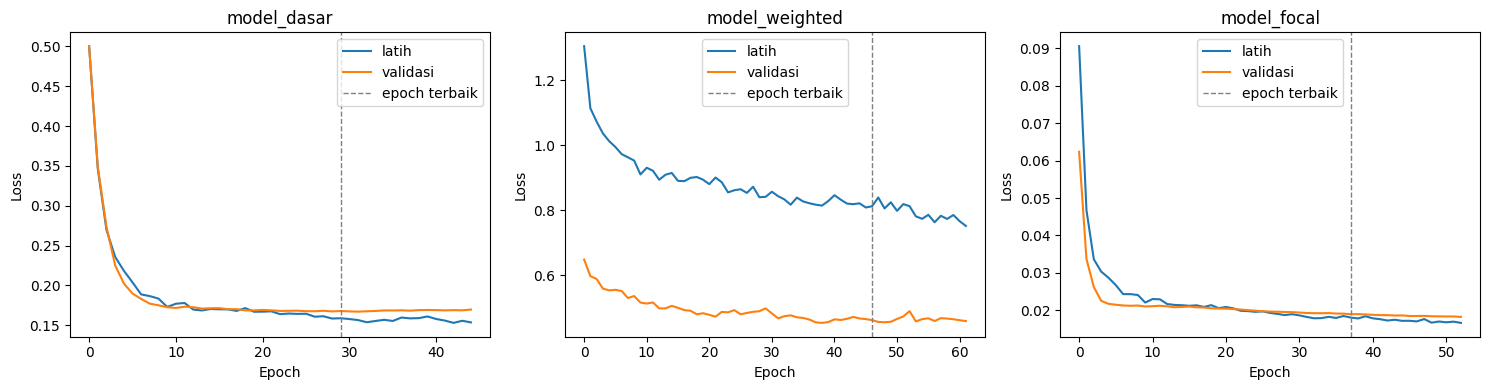

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, (nama, m) in zip(axes, log["model"].items()):
    ax.plot(m["history"]["loss"], label="latih")
    ax.plot(m["history"]["val_loss"], label="validasi")
    ax.axvline(m["epoch_terbaik"] - 1, color="gray", ls="--", lw=1, label="epoch terbaik")
    ax.set_title(f"model_{nama}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
plt.tight_layout()
plt.show()

## 7. (Opsional) Memilih α untuk focal loss
Di Keras, α adalah bobot kelas **stroke**. Nilai bawaan paper (0,25) justru memberi bobot lebih kecil ke kasus stroke. Sel ini membandingkan beberapa α **hanya di data validasi**. Kalau α lain jelas lebih baik, ubah `CONFIG["alpha"]` di bagian 4, lalu jalankan ulang bagian 5. Tabelnya bisa jadi bukti di laporan A.5e.

In [ ]:
hasil_alpha = []
for a in [0.25, 0.5, 0.75]:
    _, hist = latih(focal_loss(CONFIG["gamma"], a), verbose=0)
    i = int(np.argmax(hist["val_auc_pr"]))
    hasil_alpha.append(dict(alpha=a, val_auc_pr=hist["val_auc_pr"][i],
                            val_recall=hist["val_recall"][i], epoch_terbaik=i + 1))
pd.DataFrame(hasil_alpha).round(3)

,alpha,val_auc_pr,val_recall,epoch_terbaik
0,0.25,0.208,0.000,38
1,0.50,0.207,0.000,24
2,0.75,0.267,0.054,52


## 8. Unduh hasil
Folder `artifacts` di Colab hilang saat sesi berakhir. Unduh zip-nya, lalu serahkan tiga model dan `train_log.json` ke Sherly.

In [ ]:
!zip -qr artifacts.zip artifacts
from google.colab import files
files.download("artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>